# EDA – Numeric analysis

Derived statistics for the SERL half-hourly aggregated statistics, 2020–2023. Each SERL row describes one group of households in one half-hour; from its mean, median, quartiles, standard deviation and standard error we derive the coefficient of variation (spread between households relative to the mean), quartile (Bowley) and Pearson skewness, the interquartile range and a 95% confidence interval for the mean.

**Inputs:** the four half-hourly files (read with `serl_utils`). **Outputs:** figures and tables inline.

Earlier versions computed these over the pooled table (all groups and units at once), tested each mean against zero (energy use cannot be negative, so the test said nothing) and added cooling degree hours above 22 °C, which are zero for annual-average UK temperatures. Those parts are removed.


In [1]:
# ===========================
# Derived statistics for SERL rows + HTML math card
# ===========================
from __future__ import annotations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

# ---------- Color scheme (FIXED: strings, no commas) ----------
PRIMARY_COLOR   = "#12436D" # deep blue
SECONDARY_COLOR = "#821952"  # plum
ACCENT_COLOR    = "#F18F01"  # golden yellow
LIGHT_BG        = "#F5F5F5"  # light gray background
DARK_TEXT       = "#333333"  # dark text

# Plotting palette (10 colors)
PALETTE = [
    PRIMARY_COLOR, SECONDARY_COLOR, ACCENT_COLOR, "#F4A259",
    "#8E6E95", "#7FB3D5", "#D98880", "#F9E79F", "#A9CCE3", "#C39BD3"
]

# ---------- Matplotlib look ----------
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#222222",
    "grid.color": "#e5e5ef",
    "grid.alpha": 0.85,
    "axes.grid": True,
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelcolor": DARK_TEXT,
    "text.color": DARK_TEXT,
    "legend.frameon": False,
})
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=PALETTE)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Times','serif']})

# ---------- Helpers ----------
def _to_num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s, errors="coerce")

def _fmt(x, digits=3):
    if pd.isna(x): return "NaN"
    if isinstance(x, (int, np.integer)): return f"{x:,}"
    x = float(x)
    if abs(x) >= 10000: return f"{x:,.0f}"
    if abs(x) >= 1000:  return f"{x:.{max(0, digits-1)}f}"
    if abs(x) >= 1:     return f"{x:.{digits}f}"
    return f"{x:.{digits+1}g}"

def prepare_frame(df: pd.DataFrame, year: int) -> pd.DataFrame:
    out = df.copy()
    # Ensure key numerics are numeric
    for c in ["mean","standard_deviation","standard_error_mean","median",
              "25th_percentile","75th_percentile","mean_temp","mean_solar","n_rounded"]:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce")
    # Half-hour index from summary_time if available
    if "halfhour_index" not in out.columns and "summary_time" in out.columns:
        t = pd.to_datetime(out["summary_time"], format="%H:%M", errors="coerce")
        out["hour"] = t.dt.hour
        out["minute"] = t.dt.minute
        out["halfhour_index"] = ((out["hour"] * 60 + out["minute"]) // 30).clip(0, 47)
    # Year columns
    if "aggregation_period" not in out.columns:
        out["aggregation_period"] = int(year)
    out["year"] = out["aggregation_period"].astype(int)
    return out

def add_all_metrics(df: pd.DataFrame, m0: float = 0.0) -> pd.DataFrame:
    out = df.copy()
    mean = _to_num(out.get("mean"))
    sd   = _to_num(out.get("standard_deviation"))
    sem  = _to_num(out.get("standard_error_mean"))
    med  = _to_num(out.get("median"))
    q1   = _to_num(out.get("25th_percentile"))
    q3   = _to_num(out.get("75th_percentile"))
    n    = _to_num(out.get("n_rounded"))
    unit = out.get("unit", pd.Series(index=out.index, dtype=object)).astype(str).str.lower()

    out["variance"]       = sd**2
    out["cv"]             = sd / mean
    out["iqr"]            = q3 - q1
    out["qcd"]            = (q3 - q1) / (q3 + q1)
    out["midhinge"]       = (q1 + q3) / 2
    out["trimean"]        = (q1 + 2*med + q3) / 4
    out["pearson_skew"]   = 3*(mean - med) / sd
    out["bowley_skew"]    = (q3 + q1 - 2*med) / (q3 - q1)
    out["ci95_lo"]        = mean - 1.96*sem
    out["ci95_hi"]        = mean + 1.96*sem

    out["n_est_from_sem"] = (sd / sem)**2

    out["tukey_lo"]       = q1 - 1.5*(q3 - q1)
    out["tukey_hi"]       = q3 + 1.5*(q3 - q1)

    out["mean_kwh"]       = np.where(unit.eq("wh"), mean/1000.0, mean)
    out["total_mean_for_sample"] = mean * n

    # Weather features (if present)
    if "mean_temp" in out.columns:
        out["HDH_18"] = np.clip(18 - out["mean_temp"], 0, None)
    if "mean_solar" in out.columns:
        out["solar_norm01"] = (out["mean_solar"] - out["mean_solar"].min()) / (
            out["mean_solar"].max() - out["mean_solar"].min() + 1e-12
        )

    num = out.select_dtypes("number").columns
    out[num] = out[num].replace([np.inf, -np.inf], np.nan)
    return out

# ---------- Pretty math card (colors fixed) ----------
def show_math_card(row: pd.Series, m0: float = 0.0):
    def _safe(x): return pd.to_numeric(x, errors="coerce")
    mean = _safe(row.get("mean"))
    sd   = _safe(row.get("standard_deviation"))
    sem  = _safe(row.get("standard_error_mean"))
    med  = _safe(row.get("median"))
    q1   = _safe(row.get("25th_percentile"))
    q3   = _safe(row.get("75th_percentile"))
    n_in = _safe(row.get("n_rounded"))
    unit = str(row.get("unit", "")).lower()


    variance = sd**2 if pd.notna(sd) else np.nan
    cv       = sd/mean if (pd.notna(sd) and pd.notna(mean) and mean!=0) else np.nan
    iqr      = q3-q1 if (pd.notna(q3) and pd.notna(q1)) else np.nan
    qcd      = (q3-q1)/(q3+q1) if (pd.notna(q3) and pd.notna(q1) and (q3+q1)!=0) else np.nan
    midhinge = (q1+q3)/2 if (pd.notna(q1) and pd.notna(q3)) else np.nan
    trimean  = (q1+2*med+q3)/4 if all(pd.notna(v) for v in [q1,med,q3]) else np.nan
    p_skew   = (3*(mean-med)/sd) if all(pd.notna(v) for v in [mean,med,sd]) and sd!=0 else np.nan
    b_skew   = ((q3+q1-2*med)/(q3-q1)) if all(pd.notna(v) for v in [q3,q1,med]) and (q3-q1)!=0 else np.nan
    ci_lo    = mean - 1.96*sem if all(pd.notna(v) for v in [mean,sem]) else np.nan
    ci_hi    = mean + 1.96*sem if all(pd.notna(v) for v in [mean,sem]) else np.nan
    n_est    = (sd/sem)**2 if all(pd.notna(v) for v in [sd,sem]) and sem>0 else np.nan
    tuk_lo   = q1 - 1.5*iqr if pd.notna(iqr) and pd.notna(q1) else np.nan
    tuk_hi   = q3 + 1.5*iqr if pd.notna(iqr) and pd.notna(q3) else np.nan
    mean_kwh = mean/1000.0 if (unit=="wh" and pd.notna(mean)) else mean
    total_m  = mean * n_in if all(pd.notna(v) for v in [mean,n_in]) else np.nan

    css = f"""
    <style>
      .math-card {{
        border: 2px solid {PRIMARY_COLOR};
        border-radius: 12px;
        padding: 20px;
        margin: 15px 0;
        background: white;
        font-family: 'Helvetica Neue', Arial, sans-serif;
        box-shadow: 0 4px 8px rgba(0,0,0,0.08);
      }}
      .math-header {{
        color: {DARK_TEXT};
        margin: 0 0 15px 0;
        font-size: 22px;
        font-weight: 700;
        border-bottom: 2px solid {ACCENT_COLOR};
        padding-bottom: 10px;
        font-family: 'Times New Roman', serif;
      }}
      .badge {{
        display: inline-block;
        padding: 4px 10px;
        border-radius: 16px;
        background: {SECONDARY_COLOR};
        color: white;
        font-size: 13px;
        margin-left: 8px;
        font-weight: 600;
      }}
      .math-grid {{ display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }}
      @media (max-width: 900px) {{ .math-grid {{ grid-template-columns: 1fr; }} }}
      .math-section h3 {{ color: {PRIMARY_COLOR}; margin: 0 0 10px 0; font-size: 18px; font-weight: 700; }}
      table.kv {{ width: 100%; border-collapse: collapse; font-size: 14px; }}
      table.kv th, table.kv td {{ padding: 8px 12px; border-bottom: 1px solid #e9e9e9; text-align: left; }}
      table.kv th {{ width: 60%; color: {DARK_TEXT}; background: {LIGHT_BG}; }}
      .formula-container {{ background: {LIGHT_BG}; border-radius: 8px; padding: 12px 14px; margin: 10px 0; }}
      .formula-title {{ color: {SECONDARY_COLOR}; font-weight: 700; margin-bottom: 6px; }}
      .formula-result {{ font-weight: 700; color: {PRIMARY_COLOR}; margin-top: 4px; display: inline-block; }}
    </style>
    """

    summary_stats = f"""
    <div class="math-section">
      <h3>Summary Statistics</h3>
      <table class="kv">
        <tr><th>Mean</th><td>{_fmt(mean)}</td></tr>
        <tr><th>Std. Deviation</th><td>{_fmt(sd)}</td></tr>
        <tr><th>Std. Error (SEM)</th><td>{_fmt(sem)}</td></tr>
        <tr><th>Median</th><td>{_fmt(med)}</td></tr>
        <tr><th>Q1 (25%)</th><td>{_fmt(q1)}</td></tr>
        <tr><th>Q3 (75%)</th><td>{_fmt(q3)}</td></tr>
        <tr><th>n</th><td>{_fmt(n_in,0)}</td></tr>
      </table>
    </div>
    """

    derived = f"""
    <div class="math-section">
      <h3>Derived Metrics</h3>
      <table class="kv">
        <tr><th>Variance (s²)</th><td>{_fmt(variance)}</td></tr>
        <tr><th>Coeff. of Variation (CV)</th><td>{_fmt(cv)}</td></tr>
        <tr><th>IQR</th><td>{_fmt(iqr)}</td></tr>
        <tr><th>QCD</th><td>{_fmt(qcd)}</td></tr>
        <tr><th>Midhinge</th><td>{_fmt(midhinge)}</td></tr>
        <tr><th>Trimean</th><td>{_fmt(trimean)}</td></tr>
        <tr><th>Pearson skew</th><td>{_fmt(p_skew)}</td></tr>
        <tr><th>Bowley skew</th><td>{_fmt(b_skew)}</td></tr>
        <tr><th>95% CI</th><td>[{_fmt(ci_lo)}, {_fmt(ci_hi)}]</td></tr>
        <tr><th>n̂ (from s/SEM)</th><td>{_fmt(n_est,0)}</td></tr>
        <tr><th>Tukey fences</th><td>[{_fmt(tuk_lo)}, {_fmt(tuk_hi)}]</td></tr>
        <tr><th>mean (kWh)</th><td>{_fmt(mean_kwh)}</td></tr>
        <tr><th>sample total ≈ x̄·n</th><td>{_fmt(total_m)}</td></tr>
      </table>
    </div>
    """

    html = f"""
    {css}
    <div class="math-card">
      <h2 class="math-header">Statistical Analysis <span class="badge">Row {row.name if hasattr(row,'name') else 'N/A'}</span></h2>
      <div class="math-grid">
        {summary_stats}
        {derived}
      </div>
    </div>
    """
    display(HTML(html))

In [2]:
import serl_utils as su

hh = su.load_half_hourly()
QUANTITIES = ["Electricity imports", "Electricity exports", "Gas"]
# whole sample, all days, Wh per half-hour: one row per year and half-hour for each quantity
base = pd.concat([add_all_metrics(su.select_slice(hh, q, "Wh")) for q in QUANTITIES], ignore_index=True)
print(f"{len(base)} rows = {len(QUANTITIES)} quantities x 4 years x 48 half-hours")

576 rows = 3 quantities x 4 years x 48 half-hours


Per quantity and year (medians over the 48 half-hours; CI half-width as % of the mean)
                          households  kWh_per_day  median_CV  median_Bowley_skew  median_Pearson_skew  CI_halfwidth_pct
quantity            year                                                                                               
Electricity exports 2020    3669.375        0.218      7.931                 NaN                0.379            25.659
                    2021   10805.208        0.301      7.731                 NaN                0.393            14.578
                    2022    8229.375        0.035     19.854                 NaN                0.151            42.896
                    2023    8527.083        0.014     29.385                 NaN                0.102            61.939
Electricity imports 2020    3743.958       11.025      0.835               0.217                0.768             2.677
                    2021   10818.333       10.083      0.763             

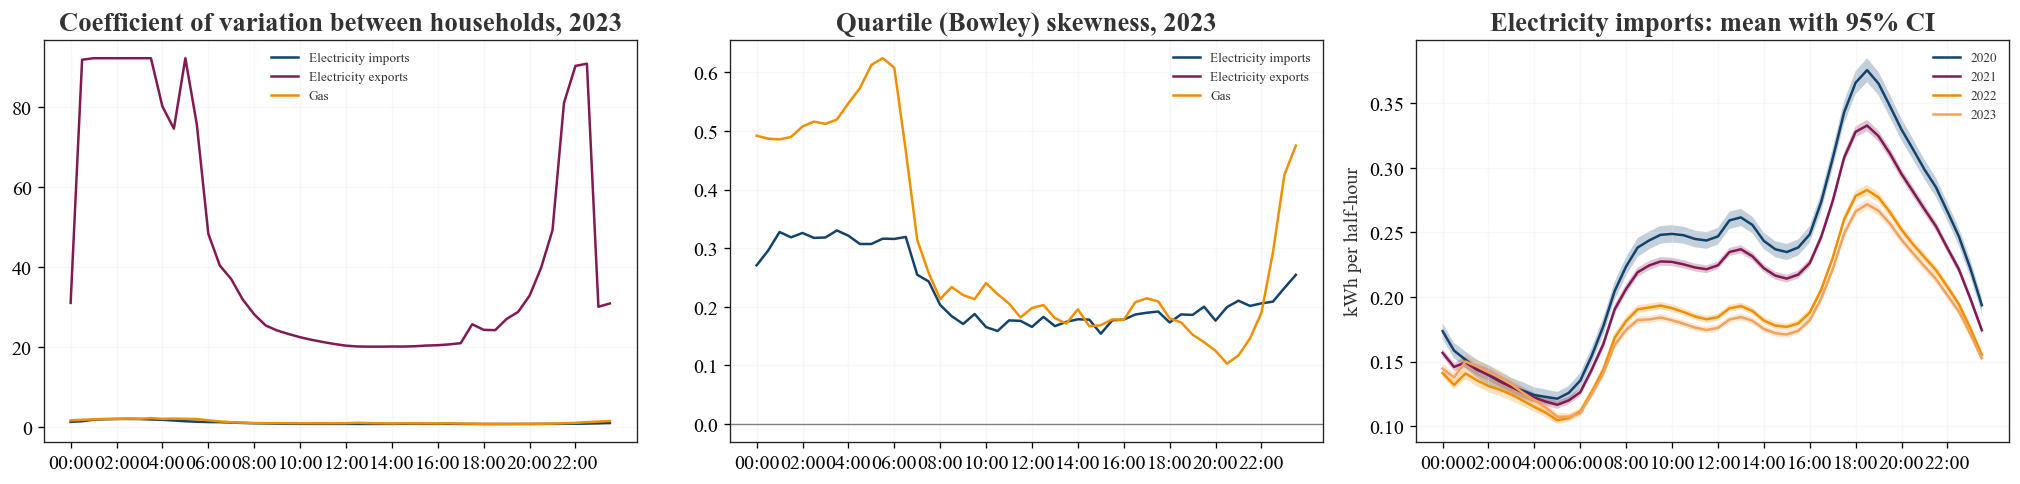

In [3]:
base["ci_halfwidth_pct"] = 100 * (base["ci95_hi"] - base["mean"]) / base["mean"]
summary = (base.groupby(["quantity", "year"])
           .agg(households=("n_rounded", "mean"),
                kWh_per_day=("mean_kwh", "sum"),            # 48 half-hours in kWh -> kWh per day
                median_CV=("cv", "median"),
                median_Bowley_skew=("bowley_skew", "median"),
                median_Pearson_skew=("pearson_skew", "median"),
                CI_halfwidth_pct=("ci_halfwidth_pct", "median")))
print("Per quantity and year (medians over the 48 half-hours; CI half-width as % of the mean)")
print(summary.round(3).to_string())

d23 = base[base["year"].eq(2023)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharex=True)
for q in QUANTITIES:
    s = d23[d23["quantity"].eq(q)]
    axes[0].plot(range(48), s["cv"], label=q)
    axes[1].plot(range(48), s["bowley_skew"], label=q)
imp = base[base["quantity"].eq("Electricity imports")]
for y, s in imp.groupby("year"):
    axes[2].plot(range(48), s["mean"] / 1000, label=str(y))
    axes[2].fill_between(range(48), s["ci95_lo"] / 1000, s["ci95_hi"] / 1000, alpha=0.25)
axes[0].set_title("Coefficient of variation between households, 2023")
axes[1].set_title("Quartile (Bowley) skewness, 2023"); axes[1].axhline(0, color="grey", linewidth=0.8)
axes[2].set_title("Electricity imports: mean with 95% CI"); axes[2].set_ylabel("kWh per half-hour")
for ax in axes:
    ax.set_xticks(range(0, 48, 4), [f"{h:02d}:00" for h in range(0, 24, 2)]); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [4]:
# math cards for two single, meaningful rows: the 2023 evening electricity peak and the 2023 morning gas peak
row_e = base[(base["quantity"] == "Electricity imports") & (base["year"] == 2023) & (base["summary_time"] == "18:30")].iloc[0]
row_g = base[(base["quantity"] == "Gas") & (base["year"] == 2023)].sort_values("mean").iloc[-1]
row_e.name = "Electricity imports, 18:30, 2023 (Wh per half-hour)"
row_g.name = f"Gas, {row_g['summary_time']} (morning peak), 2023 (Wh per half-hour)"
print("Whole sample, 2023: the evening electricity peak and the gas peak")
show_math_card(row_e)
show_math_card(row_g)

Whole sample, 2023: the evening electricity peak and the gas peak


Mean,271.761
Std. Deviation,186.815
Std. Error (SEM),1.961
Median,227.495
Q1 (25%),144.220
Q3 (75%),349.094
n,"9,080"
Variance (s²),"34,900"
Coeff. of Variation (CV),0.6874
IQR,204.874
QCD,0.4153


Mean,1274.99
Std. Deviation,1304.76
Std. Error (SEM),15.313
Median,879.699
Q1 (25%),310.524
Q3 (75%),1844.11
n,"7,260"
Variance (s²),"1,702,401"
Coeff. of Variation (CV),1.023
IQR,1533.59
QCD,0.7118


**Reading the results**
- The coefficient of variation is about 0.7–0.9 during the day and rises above 1 overnight (up to about 2 in 2023): at night the spread between households is larger than the average itself, because a minority (e.g. storage heaters, EV charging) uses far more than most.
- Mean above median (positive skew) at every half-hour means a minority of high users pulls the average up, so medians describe a typical household better than means.
- With around 10,000 households per half-hour, confidence intervals for the *mean* are narrow (a few per cent), so year-to-year differences in the profile are statistically clear even when small.
